In [1]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, normalize,
                                   Binarizer, OrdinalEncoder, LabelEncoder, OneHotEncoder)
DATA = "../../data/"


In [6]:
D = pd.read_csv(DATA + "Iris_Dataset.csv")
D.info()
print(D.describe(), D.shape, D.columns, D.head(), sep="\n")

sub = D[["sepal_length", "petal_width"]]
print(sub.head(20))

D_copy = D.copy()

X, y = D.drop(columns="species"), D["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(len(X_train), len(X_test), len(X_train) / len(D), len(X_test) / len(D))
print(y_train.value_counts(normalize=True), y_test.value_counts(normalize=True))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000
(15

In [5]:
with open(DATA + "txt_file.txt", encoding="utf-8") as f:
    for line in f:
        print(line.rstrip("\n"))

news = fetch_20newsgroups(subset="train")
print(len(news.data), len(news.target_names))
print(news.data[0])
print(news.target[0], news.target_names[news.target[0]])
print(news.target_names)
print(pd.Series([len(d.split()) for d in news.data]).describe())  


0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2
11314 20
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Thanks,
- IL
   ---- brought to you by your neighborhood Lerxst ----





7 rec.autos
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.

Index(['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary',
       'Bonus %', 'Senior Management', 'Team'],
      dtype='object')
First Name            object
Gender                object
Start Date            object
Last Login Time       object
Salary                 int64
Bonus %              float64
Senior Management     object
Team                  object
dtype: object
  First Name  Gender Start Date Last Login Time  Salary  Bonus %  \
0    Douglas    Male   8/6/1993        12:42 PM   97308    6.945   
1     Thomas    Male  3/31/1996         6:53 AM   61933    4.170   
2      Maria  Female  4/23/1993        11:17 AM  130590   11.858   
3      Jerry    Male   3/4/2005         1:00 PM  138705    9.340   
4      Larry    Male  1/24/1998         4:47 PM  101004    1.389   

  Senior Management             Team  
0              True        Marketing  
1              True              NaN  
2             False          Finance  
3              True          Finance  
4     

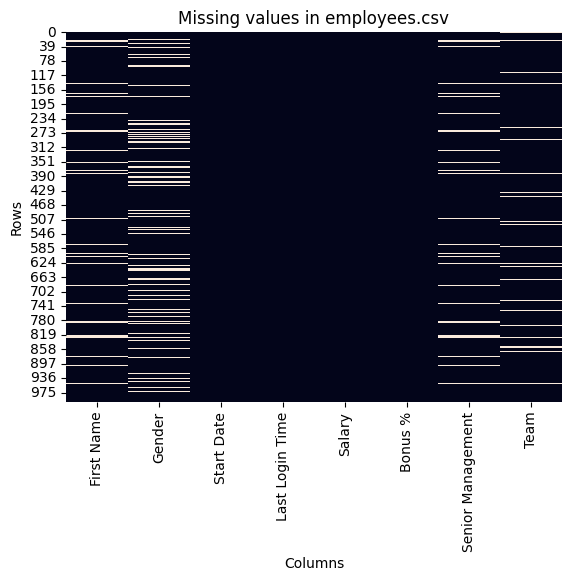

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64
                   before  after
First Name             68     68
Gender                146      0
Start Date              1      1
Last Login Time         1      1
Salary                  1      0
Bonus %                 1      0
Senior Management      68      0
Team                   44      0


In [4]:
E = pd.read_csv(DATA + "employees.csv")
print(E.columns, E.dtypes, E.head(), sep="\n")
print(E.isna().sum())

sns.heatmap(E.isna(), cbar=False)
plt.title("Missing values in employees.csv"); plt.xlabel("Columns"); plt.ylabel("Rows"); plt.show()

E2 = E.copy()
E2.loc[len(E2)] = ["-", "na", "-", "-", "na", "na", "-", "-"]
print(E2.isna().sum())   # unchanged: '-' and 'na' are plain strings

# Rule: strip + lowercase each value; if it is in `markers`, replace with NaN
markers = ["-", "na", "n/a", "", "?"]
E2 = E2.apply(lambda c: c.mask(c.astype(str).str.strip().str.lower().isin(markers)))
E2[["Salary", "Bonus %"]] = E2[["Salary", "Bonus %"]].apply(pd.to_numeric)
before = E2.isna().sum()

num, cat = ["Salary", "Bonus %"], ["Gender", "Senior Management", "Team"]
E3 = E2.copy()
E3[num] = SimpleImputer(strategy="median").fit_transform(E3[num])
E3[cat] = SimpleImputer(strategy="most_frequent").fit_transform(E3[cat])
print(pd.DataFrame({"before": before, "after": E3.isna().sum()}))

In [3]:
M = np.array([[1, -1, 2], [2, 0, 0], [0, 1, -1]], dtype=float)
for s in [StandardScaler(), MinMaxScaler(), MaxAbsScaler(), RobustScaler()]:
    print(type(s).__name__, s.fit_transform(M), sep="\n")
print("normalize (L2)", normalize(M), sep="\n")
print("Binarizer(threshold=0)", Binarizer(threshold=0).fit_transform(M), sep="\n")


StandardScaler
[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]
MinMaxScaler
[[0.5        0.         1.        ]
 [1.         0.5        0.33333333]
 [0.         1.         0.        ]]
MaxAbsScaler
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]
RobustScaler
[[ 0.         -1.          1.33333333]
 [ 1.          0.          0.        ]
 [-1.          1.         -0.66666667]]
normalize (L2)
[[ 0.40824829 -0.40824829  0.81649658]
 [ 1.          0.          0.        ]
 [ 0.          0.70710678 -0.70710678]]
Binarizer(threshold=0)
[[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [2]:
X4 = [["male", "from US", "uses Safari"], ["female", "from Europe", "uses Safari"],
      ["female", "from Asia", "uses Firefox"], ["male", "from Africa", "uses Chrome"]]
y4 = ["US", "France", "Japan", "Algeria"]

oe = OrdinalEncoder()
print(oe.fit_transform(X4), oe.categories_)

le = LabelEncoder()
print(le.fit_transform(y4), list(le.classes_))   

ohe = OneHotEncoder()
print(ohe.fit_transform(np.array(y4).reshape(-1, 1)).toarray(), ohe.categories_)


[[1. 3. 2.]
 [0. 2. 2.]
 [0. 1. 1.]
 [1. 0. 0.]] [array(['female', 'male'], dtype=object), array(['from Africa', 'from Asia', 'from Europe', 'from US'], dtype=object), array(['uses Chrome', 'uses Firefox', 'uses Safari'], dtype=object)]
[3 1 2 0] [np.str_('Algeria'), np.str_('France'), np.str_('Japan'), np.str_('US')]
[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]] [array(['Algeria', 'France', 'Japan', 'US'], dtype='<U7')]
